# 04 · Recolocación condicional con 19 réplicas

El modelo traslada cada traza conservando forma, longitud y orientación dentro del mismo polígono. La prueba evalúa T=D0−D2 con semilla 42 y cola bilateral. Se demuestra la ejecución con pocas réplicas.

In [1]:
from pathlib import Path
import os
import sys
import time
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image
from shapely.geometry import LineString, box
from pyproj import CRS

started_wall, started_cpu = time.perf_counter(), time.process_time()
repository = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/musa").is_dir())
sys.path.insert(0, str(repository / "src"))
sys.path.insert(0, str(repository / "scripts"))
from musa import MUSA, ScalingOptions, assess_lineament_scaling, write_scaling_reports
crs = CRS.from_proj4("+proj=eqc +R=6371000 +units=m +no_defs +type=crs")
lines = [LineString([(1000, 1500), (9000, 6500)])]
domain = box(0, 0, 10000, 10000)
scales = np.geomspace(10, 1000, 16)
model = MUSA.from_line_geometries(lines, domain, crs, q_values=[0, 1, 2])
output = Path(os.environ.get("MUSA_NOTEBOOK_OUTPUT_ROOT", repository / "outputs/notebooks")) / "04_trace_relocation"
output.mkdir(parents=True, exist_ok=True)
def save_figure(figure, name):
    target = output / (name + ".png")
    figure.savefig(target, dpi=120, bbox_inches="tight")
    display(Image(filename=str(target)))
    plt.close(figure)
print("Synthetic inputs; unlocated model metres. Outputs:", output.name)


Synthetic inputs; unlocated model metres. Outputs: 04_trace_relocation


## Simulación y reporte

El intervalo de 16 escalas 10…1000 m queda fijo. La política inform_q0_q2 conserva la advertencia de orden junto al contraste.

,observed,p_value,p_holm,minimum_p,holm_family_size
0,-0.006717,0.7,0.7,0.1,1


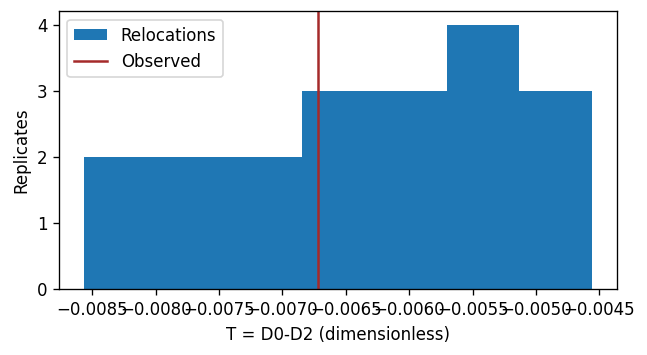

19 replicates: minimum two-sided p=0.1; rejection at 0.05 is unresolved.


In [2]:
options = ScalingOptions(1, null_replicates=19, seed=42, renyi_order_policy="inform_q0_q2", null_tail="two_sided")
report = assess_lineament_scaling(model, scales, options)
assert report["null"]["status"] == "complete"
assert len(report["null"]["values"]) == 19
write_scaling_reports(output / "assessment", [report])
saved = json.loads((output / "assessment/scaling_support.json").read_text())["supports"][0]["null"]
display(pd.DataFrame([{key:saved[key] for key in ["observed", "p_value", "p_holm", "minimum_p", "holm_family_size"]}]))
figure, ax = plt.subplots(figsize=(6, 3))
ax.hist(saved["values"], bins=7, label="Relocations")
ax.axvline(saved["observed"], color="brown", label="Observed")
ax.set(xlabel="T = D0-D2 (dimensionless)", ylabel="Replicates")
ax.legend()
save_figure(figure, "null_distribution")
assert np.isclose(saved["minimum_p"], .1)
print("19 replicates: minimum two-sided p=0.1; rejection at 0.05 is unresolved.")

## Una familia declarada

Aquí se solicita un soporte y Holm conserva su p. El recorrido QGIS incluye diez soportes y obtiene p de Holm=1; la familia forma parte de la lectura.

In [3]:
print("Raw p:", saved["p_value"], "Holm p:", saved["p_holm"])
assert not saved["reject_relocation_at_0_05"]
assert not saved["resolution_sufficient_for_family_at_0_05"]

Raw p: 0.7 Holm p: 0.7


In [4]:
metrics = dict(wall_seconds=time.perf_counter()-started_wall,
               cpu_seconds_kernel=time.process_time()-started_cpu)
(output / "execution.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
print(json.dumps(metrics))


{"wall_seconds": 3.7934291999999914, "cpu_seconds_kernel": 3.765625}
